# 02 · Do neural networks beat the classical models? An LSTM and a small Transformer on the same split

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/maryammahmoudi1993/LSTM_passenges_prediction/blob/main/notebooks/02_lstm_and_transformer_on_the_same_split.ipynb)

**What this notebook does.** Notebook 01 set up one fair test and ran the classical models. Here an **LSTM** (the model I tried in 2023) and a **small Transformer** take exactly the same test,
under the same rules, and we put *all* models in one table and one plot. The honest question is not "can a neural network forecast?" but "does it beat the simple models, and what does it need to get there?"

*Time: about 15 minutes (the cells run about eight minutes on a laptop CPU). Prerequisite: notebook 01.*

## 1 · Then versus now (short)

In 2023 the LSTM notebook ended in an error and its windows contained the answer (see [`legacy/ABOUT.md`](../legacy/ABOUT.md)). Today the same idea is run properly:
**windows that end strictly before the month to predict** (tested in `tests/`), a forecast that provably cannot depend on later data, a validation set for choices, a test set used once, several seeds, and the classical models next to them.

In [1]:
import os, pathlib, subprocess, sys

# On Google Colab the repository is not there yet, so we download it once (and install Prophet).
if "google.colab" in sys.modules and not pathlib.Path("src").exists():
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/maryammahmoudi1993/LSTM_passenges_prediction.git"], check=True)
    os.chdir("LSTM_passenges_prediction/notebooks")

sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent))   # lets us import from src/

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import neural as nn          # import before TensorFlow: it sets two environment variables
from src import forecasting as fc
from src.forecasting import save_figure

np.random.seed(fc.SEED)            # (the classical models below are deterministic; the seed matters from notebook 02 on)
plt.rcParams["figure.dpi"] = 100

## 2 · The rules for the neural models

Same split as before: **train** = first 96 months, **validation** = next 24, **test** = last 24, in time order. Additional rules that are specific to neural networks:

1. **Input:** the last 12 months before the month to predict (a window). The window never contains the target or anything later; a test in `tests/` changes the future and checks that the forecast stays the same.
2. **Scaling uses the training months only** (never the validation or test months).
3. **Training stops early** when the loss on the validation windows stops improving; the weights of the best epoch are kept. The validation months are used for this and for choosing the model size.
4. **Final models are re-trained on train + validation** for the number of epochs that early stopping found (the same data the classical models see before the test), and the test months are used **once**.
5. **Seeds:** neural networks depend on random starting weights, so every result is the average of **5 seeds** (42, 1, 2, 3, 4), with the smallest and largest value.

The two tasks are the same as in notebook 01: **A** one month ahead from the true last 12 months; **B** 24 months ahead from the end of 1958, where the model has to feed its own predictions back as inputs (*recursive* forecasting).

## 3 · The two models in a few lines

**LSTM.** Reads the 12 months one by one from the oldest to the newest and keeps a memory (see the gated memory of an LSTM: it decides what to remember and what to forget); a final layer turns the memory into the next value. We try 16 and 32 memory units.

**Small Transformer.** Instead of reading in order, every month *looks at all the other months* and decides how much attention to give each. For a query $Q$, keys $K$ and values $V$ (all computed from the months):

$$\mathrm{Attention}(Q,K,V)=\mathrm{softmax}\!\left(\frac{QK^{\top}}{\sqrt{d}}\right)V$$

- $QK^{\top}$: how well each month's "question" matches every month's "label" (a table of scores);
- $d$: the size of the vectors; dividing by $\sqrt d$ keeps the scores in a reasonable range;
- softmax: turns each row of scores into weights that are positive and add up to 1 (the *attention weights*);
- multiplying by $V$: each month collects a weighted mixture of the others.

Our Transformer has one or two such blocks, 16-dimensional vectors, 2 heads and a learned position for each of the 12 months. It is tiny (a few thousand numbers) because we have only about 100 training months.

**Two ways to show the data.** A neural network is bad at extrapolating beyond the values it has seen, and our test months are the highest of all. So we compare two representations of the same information:

- **levels:** the standardised logarithm of the series;
- **year-over-year change** ("yoy"): $\log y_t-\log y_{t-12}$, standardised. The forecast is the value of the same month last year times the predicted change. This removes the trend and the yearly pattern *before* the network sees the data.

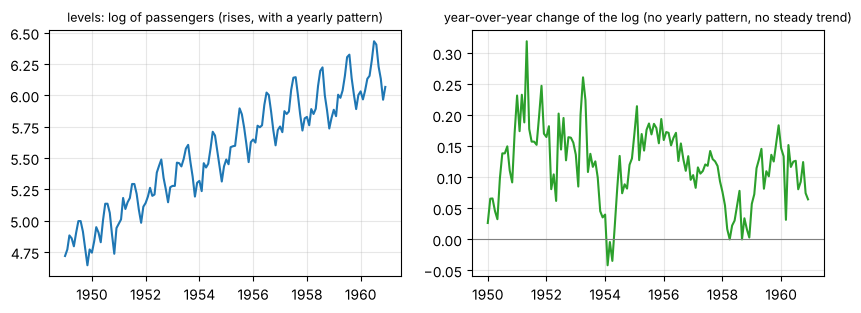

In [2]:
series = fc.load_series()
train, validation, test = fc.split(series)
fig = fc.plot_representations(series)
save_figure(fig, "02_representations.png")
plt.show()

**What to notice.** *Left, levels:* the series rises and has a yearly pattern, so the values at the end (the test months) are higher than anything in the training months, and a network has to extrapolate.
*Right, year-over-year change:* once we look at the change from the same month last year, the trend and the yearly pattern are gone. The values wander between about 0 and 0.3 (growth of 0% to about 35% a year), and the test months (1959 and 1960) lie roughly within the range seen before. The network only has to predict how much faster or slower this year grows than last year.

*Figure: the logarithm of the series (left) and its year-over-year change (right).*

## 4 · Choosing the size and the representation on the validation months

Eight candidates (2 representations x LSTM with 16 or 32 units, Transformer with 1 or 2 blocks), each trained with 3 seeds (42, 1, 2) on the training windows, with early stopping on the validation windows.
The score is the **MAE of the one-month-ahead forecasts of the 24 validation months**, in thousands of passengers.
For comparison, from notebook 01: seasonal naive 26.4, and the best classical model (Holt-Winters) 8.5.

In [3]:
grid = [("lstm", {"units": 16}), ("lstm", {"units": 32}), ("transformer", {"blocks": 1}), ("transformer", {"blocks": 2})]
configs = [(kind, {**size, "rep": rep}) for rep in ("level", "yoy") for kind, size in grid]

start = time.time()
validation_runs = {}
for kind, config in configs:
    key = (kind, tuple(sorted(config.items())))
    maes, epochs = [], []
    for seed in (42, 1, 2):
        model, best_epoch, rep = nn.train(kind, config, series, fc.N_TRAIN, fc.N_TRAIN + fc.N_VAL, seed)
        maes.append(fc.mae(validation, nn.one_step(model, rep, series, fc.N_TRAIN, fc.N_VAL)))
        epochs.append(best_epoch)
    validation_runs[key] = (np.mean(maes), maes, epochs)
    print(f"{kind:12s} {str(config):38s} validation MAE {np.mean(maes):5.1f}  (seeds: {', '.join(f'{m:.1f}' for m in maes)};  best epochs {epochs})")
print(f"({time.time() - start:.0f} s)")

lstm         {'units': 16, 'rep': 'level'}          validation MAE  37.9  (seeds: 23.0, 30.0, 60.6;  best epochs [127, 114, 12])


lstm         {'units': 32, 'rep': 'level'}          validation MAE  34.1  (seeds: 23.0, 24.5, 54.7;  best epochs [102, 76, 8])


transformer  {'blocks': 1, 'rep': 'level'}          validation MAE  35.7  (seeds: 30.7, 35.6, 40.8;  best epochs [152, 200, 200])


transformer  {'blocks': 2, 'rep': 'level'}          validation MAE  38.6  (seeds: 39.7, 29.4, 46.7;  best epochs [85, 167, 1])


lstm         {'units': 16, 'rep': 'yoy'}            validation MAE  14.3  (seeds: 15.2, 13.2, 14.6;  best epochs [21, 19, 23])


lstm         {'units': 32, 'rep': 'yoy'}            validation MAE  14.5  (seeds: 13.8, 15.5, 14.3;  best epochs [16, 18, 17])


transformer  {'blocks': 1, 'rep': 'yoy'}            validation MAE  10.6  (seeds: 10.1, 11.8, 9.9;  best epochs [50, 4, 35])


transformer  {'blocks': 2, 'rep': 'yoy'}            validation MAE  11.2  (seeds: 8.5, 12.6, 12.4;  best epochs [21, 39, 11])
(220 s)


**What to notice** (validation MAE in thousands of passengers; seasonal naive 26.4, Holt-Winters 8.5):

- **Levels:** all four candidates are worse than seasonal naive (34.1 to 38.6 on average), and the seeds disagree wildly (for the 16-unit LSTM from 23.0 to 60.6; one run stopped after only 12 epochs). A network trained on levels cannot cope with values above the training range.
- **Year-over-year changes:** all four are much better (10.6 to 14.5), close to Holt-Winters (8.5) but not better, and the seeds agree much more (for example 13.2 to 15.5).
- The **representation matters far more than the size** of the model: 16 versus 32 units or 1 versus 2 blocks changes the result by less than 1 point on average, the representation by more than 20.

In [4]:
chosen = {}
for rep_name in ("level", "yoy"):
    for model_kind in ("lstm", "transformer"):
        options = [(v[0], k) for k, v in validation_runs.items() if k[0] == model_kind and dict(k[1])["rep"] == rep_name]
        score, key = min(options)
        config = dict(key[1])
        epochs = int(max(10, np.median(validation_runs[key][2])))
        chosen[(model_kind, rep_name)] = (config, epochs)
        print(f"{model_kind:12s} {rep_name:6s} -> {config}   final training epochs: {epochs}")

lstm         level  -> {'rep': 'level', 'units': 32}   final training epochs: 76
transformer  level  -> {'blocks': 1, 'rep': 'level'}   final training epochs: 200
lstm         yoy    -> {'rep': 'yoy', 'units': 16}   final training epochs: 21
transformer  yoy    -> {'blocks': 1, 'rep': 'yoy'}   final training epochs: 35


**What to notice.** The sizes chosen on the validation months (and the number of epochs for the final training, the median of the epochs at which early stopping stopped): LSTM on levels 32 units (76 epochs), Transformer on levels 1 block (200 epochs: the maximum, the loss was still improving), LSTM on year-over-year changes 16 units (21 epochs), Transformer on year-over-year changes 1 block (35 epochs).

### Check yourself

1. Why do we re-train the chosen model on train + validation before the test, and why with a *fixed* number of epochs?
2. Why is the average over 5 seeds more trustworthy than one run?

<details>
<summary>Answers</summary>


1. The validation months are the most recent data; leaving them out would waste information that the classical models also get. After re-training there is no validation data left for early stopping, so we reuse the number of epochs that early stopping chose before.
2. The random starting weights change the result from run to run (see how much the validation MAE varies between seeds above). An average over seeds, together with the smallest and largest value, shows how much of a difference is luck.

</details>

## 5 · The final grade: the test months, used once

All four neural variants (LSTM and Transformer, each with levels and with year-over-year changes), 5 seeds each, trained on train + validation, evaluated on the test months.
The classical models are re-evaluated here with the settings that notebook 01 chose on its validation months (so that all numbers come from one notebook).

In [5]:
test_start, seeds = fc.N_TRAIN + fc.N_VAL, (42, 1, 2, 3, 4)
all_series = series

classical = {"naive": (fc.naive, fc.naive), "seasonal naive": (fc.seasonal_naive, fc.seasonal_naive),
             "SARIMA": (fc.sarima((1, 1, 0), (0, 1, 1)), fc.sarima((1, 1, 0), (0, 1, 1))),
             "Holt-Winters": (fc.holt_winters("add", "mul", damped=True), fc.holt_winters("add", "mul")),
             "Prophet": (fc.prophet("multiplicative"), fc.prophet("multiplicative"))}
forecasts = {"A": {}, "B": {}}
start = time.time()
for name, (forecaster_a, forecaster_b) in classical.items():
    forecasts["A"][name] = [fc.walk_forward(forecaster_a, series, test_start, fc.N_TEST)]
    forecasts["B"][name] = [fc.multi_step(forecaster_b, series, test_start, fc.N_TEST)]
print(f"classical models: {time.time() - start:.0f} s")

names = {("lstm", "level"): "LSTM (levels)", ("lstm", "yoy"): "LSTM (yoy)",
         ("transformer", "level"): "Transformer (levels)", ("transformer", "yoy"): "Transformer (yoy)"}
attention_models = {}
start = time.time()
for (model_kind, rep_name), (config, epochs) in chosen.items():
    label = names[(model_kind, rep_name)]
    forecasts["A"][label], forecasts["B"][label] = [], []
    for seed in seeds:
        model, attention, rep = nn.train_final(model_kind, config, series, test_start, seed, epochs)
        forecasts["A"][label].append(nn.one_step(model, rep, series, test_start, fc.N_TEST))
        forecasts["B"][label].append(nn.recursive(model, rep, series, test_start, fc.N_TEST))
        if seed == 42:
            attention_models[label] = (attention, rep)
print(f"neural models (5 seeds each, final training and forecasts): {time.time() - start:.0f} s")

classical models: 7 s


neural models (5 seeds each, final training and forecasts): 148 s


In [6]:
rows, table = [], []
for name in forecasts["A"]:
    cells = {}
    for task in ("A", "B"):
        maes = np.array([fc.mae(test, p) for p in forecasts[task][name]])
        rmses = np.array([fc.rmse(test, p) for p in forecasts[task][name]])
        mapes = np.array([fc.mape(test, p) for p in forecasts[task][name]])
        cells[task] = (maes.mean(), maes.min(), maes.max(), rmses.mean(), mapes.mean())
    rows.append((name, *cells["A"][:3], *cells["B"][:3]))
    table.append({"model": name, "A: MAE": cells["A"][0], "A: range": f"{cells['A'][1]:.1f}-{cells['A'][2]:.1f}", "A: MAPE %": cells["A"][4],
                  "B: MAE": cells["B"][0], "B: range": f"{cells['B'][1]:.1f}-{cells['B'][2]:.1f}", "B: MAPE %": cells["B"][4]})
print(pd.DataFrame(table).set_index("model").round(1).to_string())
print("\n(neural models: mean over 5 seeds and the smallest-largest MAE; classical models: one deterministic run)")

                      A: MAE   A: range  A: MAPE %  B: MAE     B: range  B: MAPE %
model                                                                             
naive                   44.2  44.2-44.2        9.7   115.2  115.2-115.2       23.6
seasonal naive          47.6  47.6-47.6       10.5    71.2    71.2-71.2       15.5
SARIMA                  12.5  12.5-12.5        2.8    42.0    42.0-42.0        9.1
Holt-Winters            12.2  12.2-12.2        2.7    29.0    29.0-29.0        6.4
Prophet                 17.6  17.6-17.6        3.8    25.5    25.5-25.5        5.4
LSTM (levels)           69.8  55.6-86.0       14.9    70.2    65.4-76.8       15.0
Transformer (levels)    47.0  40.1-50.4        9.8    85.9   67.9-102.3       18.0
LSTM (yoy)              11.7  11.3-12.4        2.6    16.0    12.3-24.2        3.5
Transformer (yoy)       15.9  14.8-17.4        3.5    30.0    21.4-45.1        6.6

(neural models: mean over 5 seeds and the smallest-largest MAE; classical models: one 

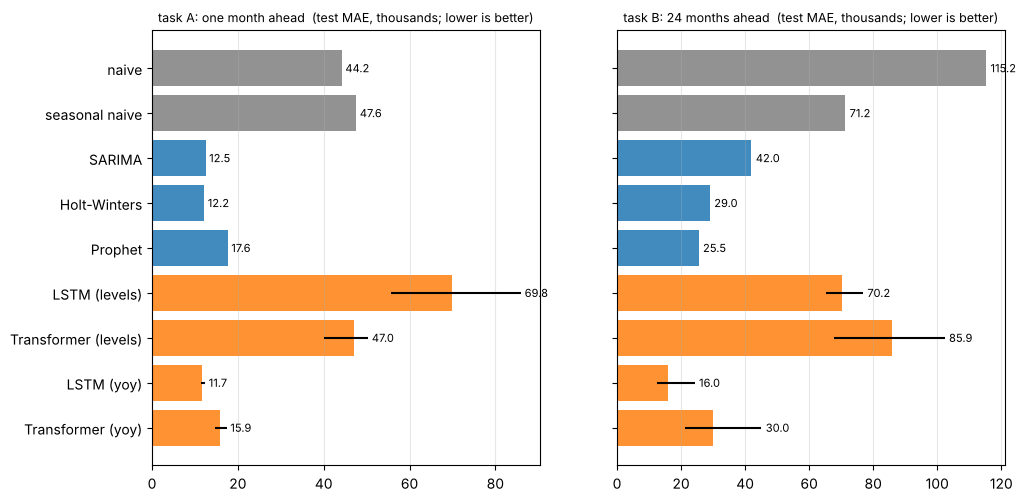

In [7]:
fig = fc.plot_conclusion(rows)
save_figure(fig, "02_conclusion.png")
plt.show()

**What to notice** (test months 1959 and 1960, used once; MAE in thousands of passengers; neural models: mean of 5 seeds and the smallest to the largest value):

| Model | Task A: MAE | Task B: MAE |
|---|---|---|
| naive / seasonal naive | 44.2 / 47.6 | 115.2 / 71.2 |
| SARIMA | 12.5 | 42.0 |
| Holt-Winters | 12.2 | 29.0 |
| Prophet | 17.6 | 25.5 |
| LSTM (levels) | 69.8 (55.6 to 86.0) | 70.2 (65.4 to 76.8) |
| Transformer (levels) | 47.0 (40.1 to 50.4) | 85.9 (67.9 to 102.3) |
| **LSTM (yoy)** | **11.7 (11.3 to 12.4)** | **16.0 (12.3 to 24.2)** |
| Transformer (yoy) | 15.9 (14.8 to 17.4) | 30.0 (21.4 to 45.1) |

- **On levels the neural networks fail**: the LSTM is worse than the naive forecast in task A (69.8 versus 44.2) and the Transformer is about as good as naive. Both cannot predict values above the range they were trained on.
- **On year-over-year changes the LSTM is the best model in both tasks**, but by very different margins. In task A it is only slightly ahead of Holt-Winters (11.7 versus 12.2) and SARIMA (12.5): the range over seeds (11.3 to 12.4) contains the Holt-Winters value, so this is a tie. In task B it is clearly ahead (16.0 versus 25.5 for Prophet, 29.0 for Holt-Winters, 42.0 for SARIMA) and even its worst seed (24.2) beats all of them, but the spread over seeds is large (12.3 to 24.2).
- **The Transformer on year-over-year changes is worse than the LSTM** (15.9 and 30.0), in line with its validation result and with only about 100 training months to learn from; it is on par with the classical models, not better.
- **Caveat on the "yoy" representation:** the forecast is last year's value times a predicted change, so it contains the seasonal-naive idea *by construction*; the network only learns the growth. Part of its success is this structure, not the network alone.
- With 24 test months and one series, only the large gaps (levels versus year-over-year, neural versus the baselines) are safe conclusions.

*Figure: test MAE of every model for both tasks (thin line: smallest to largest over the five seeds).*

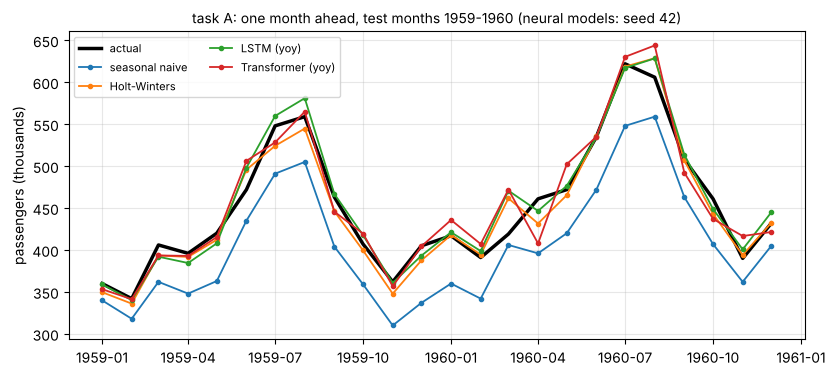

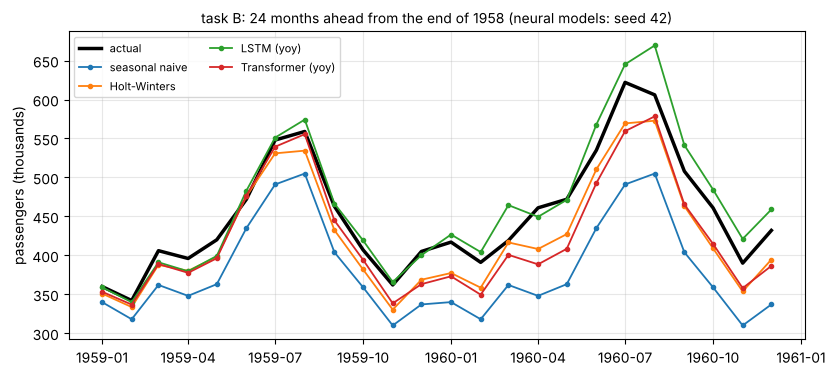

In [8]:
for task, title in [("A", "task A: one month ahead, test months 1959-1960 (neural models: seed 42)"),
                    ("B", "task B: 24 months ahead from the end of 1958 (neural models: seed 42)")]:
    shown = {name: forecasts[task][name][0] for name in ["seasonal naive", "Holt-Winters", "LSTM (yoy)", "Transformer (yoy)"]}
    fig = fc.plot_forecasts(test, shown, title)
    save_figure(fig, f"02_forecasts_task_{task.lower()}.png")
    plt.show()

**What to notice.** *Task A:* all four models follow the actual curve closely; the seasonal-naive line sits clearly below it all the time (the series grows). *Task B (seed 42):* the LSTM overshoots the summer of 1960 (about 645 and 670 thousand against 622 and 606 actual), whereas Holt-Winters and the Transformer fall short of it (about 570 to 580). Such over- and undershoots at the peaks are what the spread over seeds in the table consists of.

*Figures: forecasts and actual values on the test months for task A and task B (neural models: the model of seed 42).*

## 6 · Looking inside the Transformer

A Transformer comes with attention weights, which are tempting to read as an explanation. For the year-over-year Transformer (seed 42), where does the *last* month of the window look?
(Attention weights show where the model *gathers information*; they are not a proof of what the prediction depends on.)

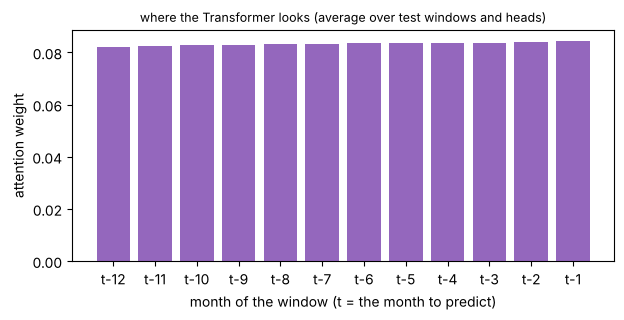

attention of the last month on t-12 ... t-1: [0.082, 0.083, 0.083, 0.083, 0.083, 0.083, 0.084, 0.084, 0.084, 0.084, 0.084, 0.084]


In [9]:
attention, rep = attention_models["Transformer (yoy)"]
weights = nn.attention_by_position(attention, rep, series, test_start, fc.N_TEST)
fig = fc.plot_attention(weights)
save_figure(fig, "02_attention.png")
plt.show()
print("attention of the last month on t-12 ... t-1:", [round(float(w), 3) for w in weights])

**What to notice.** The attention is **almost exactly uniform**: every one of the twelve months gets about 0.083 (that is 1/12), a tiny bit more for the most recent months (0.082 for t-12 to 0.084 for t-1). After 35 epochs on about 100 windows this small Transformer has *not* learned to focus on particular months (for instance the same month last year): it behaves almost like an average over the window.
So here the attention weights explain nothing; they only tell us that the model did not learn a sharp pattern. (We did not test whether a larger model or more data would change this.)

*Figure: average attention of the last month of a window on each of the twelve months.*

## 7 · Common mistakes

- **Letting the window contain the target** (the 2023 mistake). Tested here by changing the future and checking that nothing moves.
- **Scaling with the whole series** (leaks the future range into the past). We use the training months only.
- **Reporting one seed.** The spread between seeds is part of the result.
- **Feeding raw trending values to a network and expecting it to extrapolate.** The representation (levels versus year-over-year change) mattered more than the model type (see above).
- **Comparing without the simple models.** A neural network that does not beat the seasonal-naive or Holt-Winters baseline has not earned its complexity.

## 8 · Recap

- With the same rules and data, the representation of the series mattered more than the choice between LSTM and Transformer.
- Neural models, properly set up, were competitive but did not clearly beat the classical models on this small series (details in the table).
- The honest conclusion is a statement about *this* series (144 points): it is not evidence for or against neural networks in general.